In [1]:
import csv
import math
import statistics
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import networkx as nx
from networkx.algorithms.community import greedy_modularity_communities

set_random_seed(2026)

# ==============================================================================
# 1. RUTAS EXACTAS DE TU PROYECTO (TODO DENTRO DE 'datos/')
# ==============================================================================
BASE_DATOS = Path("datos")
CARPETA_SALIDAS = BASE_DATOS / "salidas"
CARPETA_SALIDAS.mkdir(parents=True, exist_ok=True)

RUTAS = {
    "2018_edges":    BASE_DATOS / "datos_twitch_2018" / "large_twitch_edges.csv",
    "2018_features": BASE_DATOS / "datos_twitch_2018" / "large_twitch_features.csv",
    "2021_edges":    BASE_DATOS / "datos_twitch_2021" / "2021-12-edges.csv",
    "2021_nodes":    BASE_DATOS / "datos_twitch_2021" / "2021-12-nodes.csv",
    "2022_edges":    BASE_DATOS / "datos_twitch_2022" / "2022-01-edges.csv",
    "2022_nodes":    BASE_DATOS / "datos_twitch_2022" / "2022-01-nodes.csv",
    "2023_100k":     BASE_DATOS / "datos_twitch_2023" / "100k_a.csv",
    "2023_full":     BASE_DATOS / "datos_twitch_2023" / "full_a.csv",
    # Opcional si haces la captura propia con la API:
    "2026_edges":    BASE_DATOS / "twitch_2026_edges.csv",
    "2026_nodes":    BASE_DATOS / "twitch_2026_nodes.csv",
}

print("Directorio actual de trabajo:", Path.cwd())
print("-" * 70)
for clave, ruta in RUTAS.items():
    estado = "✅ OK" if ruta.exists() else "❌ NO ENCONTRADO"
    print(f"{clave:15s} -> {estado:16s} | {ruta}")

Directorio actual de trabajo: /home/andrea/clase/cuarto/MATI/Proyecto-MATI
----------------------------------------------------------------------
2018_edges      -> ✅ OK             | datos/datos_twitch_2018/large_twitch_edges.csv
2018_features   -> ✅ OK             | datos/datos_twitch_2018/large_twitch_features.csv
2021_edges      -> ✅ OK             | datos/datos_twitch_2021/2021-12-edges.csv
2021_nodes      -> ✅ OK             | datos/datos_twitch_2021/2021-12-nodes.csv
2022_edges      -> ✅ OK             | datos/datos_twitch_2022/2022-01-edges.csv
2022_nodes      -> ✅ OK             | datos/datos_twitch_2022/2022-01-nodes.csv
2023_100k       -> ✅ OK             | datos/datos_twitch_2023/100k_a.csv
2023_full       -> ✅ OK             | datos/datos_twitch_2023/full_a.csv
2026_edges      -> ✅ OK             | datos/twitch_2026_edges.csv
2026_nodes      -> ✅ OK             | datos/twitch_2026_nodes.csv


In [2]:
# ==============================================================================
# 2. FUNCIONES COMUNES DEL PROYECTO
# ==============================================================================
def top_diccionario(dic, k=10):
    return sorted(dic.items(), key=lambda par: par[1], reverse=True)[:k]

def bfs_distancias(H, origen):
    dist = {origen: 0}
    cola = [origen]
    i = 0
    while i < len(cola):
        u = cola[i]; i += 1
        for v in H.neighbors(u):
            if v not in dist:
                dist[v] = dist[u] + 1
                cola.append(v)
    return dist

def estimar_distancia_media(H, n_origenes=200, seed=2026):
    if H.order() <= 1:
        return 0.0
    set_random_seed(seed)
    vertices = list(H.vertices())
    origenes = sample(vertices, min(n_origenes, len(vertices)))
    suma, cuenta = 0, 0
    for u in origenes:
        dist = bfs_distancias(H, u)
        suma += sum(d for v, d in dist.items() if v != u)
        cuenta += len(dist) - 1
    return float(suma) / float(cuenta) if cuenta else 0.0

def calcular_paradoja_amistad(H):
    menos, mas, igual = 0, 0, 0
    for v in H.vertices():
        vec = H.neighbors(v)
        if not vec:
            continue
        media_vec = float(sum(H.degree(u) for u in vec)) / float(len(vec))
        gv = float(H.degree(v))
        if gv < media_vec:
            menos += 1
        elif gv > media_vec:
            mas += 1
        else:
            igual += 1
    tot = menos + mas + igual
    return menos, mas, float(100.0 * menos / tot) if tot else 0.0

def cargar_subgrafo_2018(idioma, usuarios_por_idioma, ruta_aristas):
    ids_idioma = set(usuarios_por_idioma[idioma])
    aristas = set()
    with ruta_aristas.open(newline="", encoding="utf-8-sig") as f:
        for fila in csv.DictReader(f):
            u = int(fila["numeric_id_1"])
            v = int(fila["numeric_id_2"])
            if u in ids_idioma and v in ids_idioma and u != v:
                aristas.add(tuple(sorted((u, v))))
    H = Graph()
    H.add_vertices(sorted(ids_idioma))
    H.add_edges(sorted(aristas))
    return H

def cargar_red_overlap(ruta_aristas, ruta_nodos=None, top_k=15):
    nombres = {}
    if ruta_nodos is not None and ruta_nodos.exists():
        with ruta_nodos.open(newline="", encoding="utf-8-sig", errors="ignore") as fn:
            for fila in csv.DictReader(fn):
                nid = fila.get("Id") or fila.get("id") or fila.get("numeric_id")
                lbl = fila.get("Label") or fila.get("label") or fila.get("username")
                if nid and lbl:
                    nombres[str(nid).strip()] = str(lbl).strip()

    vecinos = defaultdict(list)
    with ruta_aristas.open(newline="", encoding="utf-8-sig", errors="ignore") as f:
        lector = csv.reader(f)
        next(lector, None)
        for fila in lector:
            if len(fila) < 2:
                continue
            u = nombres.get(fila[0].strip(), fila[0].strip()).lower()
            v = nombres.get(fila[1].strip(), fila[1].strip()).lower()
            try:
                w = float(fila[2]) if len(fila) > 2 else 1.0
            except ValueError:
                w = 1.0
            if u != v:
                vecinos[u].append((w, v))
                vecinos[v].append((w, u))

    aristas = set()
    for u, lista in vecinos.items():
        for w, v in sorted(lista, key=lambda x: x[0], reverse=True)[:top_k]:
            aristas.add(tuple(sorted((u, v))))
    H = Graph()
    H.add_vertices(sorted(vecinos.keys()))
    H.add_edges(sorted(aristas))
    return H

def cargar_red_kaggle(ruta_csv, max_filas=1500000, top_streamers=1000, min_comunes=5, top_k=15):
    audiencia = defaultdict(set)
    with ruta_csv.open(newline="", encoding="utf-8-sig", errors="ignore") as f:
        lector = csv.reader(f)
        for i, fila in enumerate(lector):
            if i >= max_filas:
                break
            if len(fila) < 3 or (i == 0 and not fila[0].strip().isdigit()):
                continue
            audiencia[fila[2].strip().lower()].add(fila[0].strip())

    top_canales = [c for c, _ in sorted(audiencia.items(), key=lambda x: len(x[1]), reverse=True)[:top_streamers]]
    vecinos = defaultdict(list)
    for c1, c2 in combinations(top_canales, 2):
        com = len(audiencia[c1] & audiencia[c2])
        if com >= min_comunes:
            vecinos[c1].append((com, c2))
            vecinos[c2].append((com, c1))

    aristas_brutas = []
    aristas_podadas = set()
    for u, lista in vecinos.items():
        for w, v in lista:
            if u < v:
                aristas_brutas.append((u, v))
        for w, v in sorted(lista, key=lambda x: x[0], reverse=True)[:top_k]:
            aristas_podadas.add(tuple(sorted((u, v))))

    G_bruto = Graph()
    G_bruto.add_vertices(top_canales)
    G_bruto.add_edges(aristas_brutas)

    G_podado = Graph()
    G_podado.add_vertices(top_canales)
    G_podado.add_edges(sorted(aristas_podadas))
    return G_bruto, G_podado

def analizar_red(nombre, H, n_origenes_bfs=150):
    n_h, m_h = int(H.order()), int(H.size())
    grados_h = [int(H.degree(v)) for v in H.vertices()]
    media_g = float(statistics.mean(grados_h))
    mediana_g = float(statistics.median(grados_h))
    max_g = int(max(grados_h))
    aislados_h = int(sum(1 for d in grados_h if d == 0))
    dens_pct = float(100.0 * (2.0 * m_h) / (n_h * (n_h - 1))) if n_h > 1 else 0.0
    cv_g = float(math.sqrt(sum((d - media_g)**2 for d in grados_h) / n_h) / media_g) if media_g else 0.0

    comps = sorted(H.connected_components(), key=len, reverse=True)
    H_gig = H.subgraph(comps[0])
    pct_gig = float(100.0 * H_gig.order() / n_h)

    dist_m = estimar_distancia_media(H_gig, n_origenes=n_origenes_bfs, seed=2026)
    diam_h = int(H_gig.diameter())
    clust_h = float(H.clustering_average())
    _, _, pct_paradoja = calcular_paradoja_amistad(H_gig)

    c_grado = {v: int(H_gig.degree(v)) for v in H_gig.vertices()}
    c_inter = H_gig.centrality_betweenness(normalized=True)
    c_cerca = H_gig.centrality_closeness()
    c_vec = nx.eigenvector_centrality(H_gig.networkx_graph(), max_iter=1000)

    coms = list(greedy_modularity_communities(H_gig.networkx_graph()))
    nucleo_150 = [v for v, _ in sorted(c_grado.items(), key=lambda x: x[1], reverse=True)[:min(150, n_h)]]
    clique_tam = int(len(H.subgraph(nucleo_150).clique_maximum()))

    print(f"\n==================== {nombre} ====================")
    print(f"Vértices: {n_h:,} | Aristas: {m_h:,} | Densidad: {dens_pct:.3f}% | Aislados: {aislados_h}")
    print(f"Grado medio: {media_g:.2f} | Mediana: {mediana_g:.1f} | Máx: {max_g} | CV: {cv_g:.3f} | Paradoja Amistad: {pct_paradoja:.1f}%")
    print(f"Comp. mayor: {int(H_gig.order()):,} ({pct_gig:.1f}%) | Dist. media: {dist_m:.3f} | Diámetro: {diam_h} | Clustering: {clust_h:.4f}")
    print(f"Comunidades: {len(coms)} | Clique núcleo (Top 150): K_{clique_tam}")
    print("  Top 5 Grado:         ", top_diccionario(c_grado, 5))
    print("  Top 5 Intermediación:", [(k, round(float(v), 5)) for k, v in top_diccionario(c_inter, 5)])
    print("  Top 5 Vector propio: ", [(k, round(float(v), 5)) for k, v in top_diccionario(c_vec, 5)])

    return {
        "red": nombre, "vertices": n_h, "aristas": m_h, "densidad_pct": dens_pct,
        "grado_medio": media_g, "mediana": mediana_g, "maximo": max_g, "cv": cv_g,
        "clustering": clust_h, "distancia": dist_m, "diametro": diam_h,
        "paradoja_pct": pct_paradoja, "comunidades": len(coms), "clique": clique_tam,
        "G_gigante": H_gig, "c_grado": c_grado, "c_inter": c_inter, "c_cerca": c_cerca, "c_vec": c_vec
    }

print("Funciones cargadas correctamente.")

Funciones cargadas correctamente.


In [3]:
# 1. Leer atributos de 2018
atributos_2018 = {}
usuarios_por_idioma = defaultdict(list)

with RUTAS["2018_features"].open(newline="", encoding="utf-8-sig") as f:
    for fila in csv.DictReader(f):
        u = int(fila["numeric_id"])
        atributos_2018[u] = fila
        idioma = (fila.get("language") or "").strip().upper()
        usuarios_por_idioma[idioma].append(u)

print(f"2018 cargado: {len(atributos_2018):,} usuarios totales en {len(usuarios_por_idioma)} idiomas.")

# 2. Construir subgrafos PT y ES
G_pt = cargar_subgrafo_2018("PT", usuarios_por_idioma, RUTAS["2018_edges"])
G_es = cargar_subgrafo_2018("ES", usuarios_por_idioma, RUTAS["2018_edges"])

# 3. Protocolo de comprobación previa sobre PT (Teorema de Whitney y conexidad)
print("\n=== PROTOCOLO DE COMPROBACIONES PREVIAS SOBRE PT (2018) ===")
print(f"¿Grafo simple no dirigido?: {(not G_pt.has_loops()) and (not G_pt.has_multiple_edges())}")
print(f"¿Apretón de manos (Σ grados = 2m)?: {sum(G_pt.degree()) == 2 * G_pt.size()}")
print(f"¿Es G_pt conexo?: {G_pt.is_connected()} ({G_pt.connected_components_number()} componentes) -> δ(G) = {min(G_pt.degree())}")

res_pt = analizar_red("2018 SNAP (PT)", G_pt)
res_es = analizar_red("2018 SNAP (ES)", G_es)

# 4. Centro, Radio, Diámetro, Vértices de corte y Bonacich en G_gigante de PT
G_gig = res_pt["G_gigante"]
bloques, v_corte = G_gig.blocks_and_cut_vertices()
puentes = list(G_gig.bridges())
exc = {v: int(e) for v, e in zip(G_gig.vertices(), G_gig.eccentricity())}
radio_pt, diam_pt = min(exc.values()), max(exc.values())
centro_pt = [v for v, e in exc.items() if e == radio_pt]

print("\n=== ROBUSTEZ, CENTRO Y DESIGUALDAD MÉTRICA EN PT (COMPONENTE GIGANTE) ===")
print(f"Vértices de corte: {len(v_corte)} | Aristas puente: {len(puentes)} | δ(G_gig) = {min(G_gig.degree())}")
print(f"Radio = {radio_pt} | Diámetro = {diam_pt} | ¿rad <= diam <= 2*rad?: {radio_pt <= diam_pt <= 2*radio_pt}")
print(f"Tamaño del Centro Z(G_gig): {len(centro_pt)} vértices -> Ejemplos: {centro_pt[:8]}")

# Centralidad de Bonacich (vértices ordenados para alinear con la matriz)
nodos_ord = sorted(G_gig.vertices())
A_np = nx.to_numpy_array(G_gig.networkx_graph(), nodelist=nodos_ord, dtype=float)
lambda_max = float(np.max(np.abs(np.linalg.eigvalsh(A_np))))
alpha_bon = 0.5 / lambda_max
c_bon = np.linalg.solve(np.eye(len(nodos_ord)) - alpha_bon * A_np, A_np @ np.ones(len(nodos_ord)))
c_bon = c_bon / np.linalg.norm(c_bon)
dic_bon = {nodos_ord[i]: float(c_bon[i]) for i in range(len(nodos_ord))}
print(f"Bonacich (lambda_max={lambda_max:.3f}, alpha={alpha_bon:.5f}) Top 5:",
      [(v, round(val, 5)) for v, val in top_diccionario(dic_bon, 5)])

# 5. Experimento de ataque dirigido (Top 20 nodos)
top20_inter = [v for v, _ in top_diccionario(res_pt["c_inter"], 20)]
top20_vec = [v for v, _ in top_diccionario(res_pt["c_vec"], 20)]
set_random_seed(2026)
azar20 = sample(list(G_gig.vertices()), 20)

print("\n=== SIMULACIÓN DE ATAQUE DIRIGIDO A PT (ELIMINANDO 20 NODOS) ===")
for etiq, borrar in [("Original", []), ("Fallo aleatorio (20)", azar20),
                     ("Ataque Autovector (Top 20)", top20_vec), ("Ataque Puentes (Top 20)", top20_inter)]:
    H_tmp = G_gig.copy()
    if borrar:
        H_tmp.delete_vertices(borrar)
    cs = sorted(H_tmp.connected_components(), key=len, reverse=True)
    print(f"  {etiq:30s} -> Componentes: {len(cs):2d} | Comp. mayor: {len(cs[0]):4d} nodos")

2018 cargado: 168,114 usuarios totales en 21 idiomas.

=== PROTOCOLO DE COMPROBACIONES PREVIAS SOBRE PT (2018) ===
¿Grafo simple no dirigido?: True
¿Apretón de manos (Σ grados = 2m)?: True
¿Es G_pt conexo?: False (93 componentes) -> δ(G) = 0

==================== 2018 SNAP (PT) ====================
Vértices: 2,536 | Aristas: 42,952 | Densidad: 1.336% | Aislados: 90
Grado medio: 33.87 | Mediana: 17.0 | Máx: 880 | CV: 1.838 | Paradoja Amistad: 93.9%
Comp. mayor: 2,442 (96.3%) | Dist. media: 2.641 | Diámetro: 7 | Clustering: 0.3031
Comunidades: 15 | Clique núcleo (Top 150): K_18
  Top 5 Grado:          [(122266, 880), (161540, 849), (55969, 713), (128589, 680), (160961, 664)]
  Top 5 Intermediación: [(161540, 0.08887), (122266, 0.07625), (55969, 0.05929), (160961, 0.05611), (128589, 0.04185)]
  Top 5 Vector propio:  [(122266, 0.16778), (161540, 0.15237), (50779, 0.14747), (8094, 0.14497), (128589, 0.14092)]

==================== 2018 SNAP (ES) ====================
Vértices: 5,699 | Arista

In [4]:
n_pt, m_pt = int(G_pt.order()), int(G_pt.size())
grados_pt = [int(G_pt.degree(v)) for v in G_pt.vertices()]
frec = Counter(grados_pt)
datos_ajuste = sorted((int(k), int(f)) for k, f in frec.items() if k > 0 and f > 0)

var('x a b c')
modelo_exp(x) = a * exp(b * x)
modelo_pot(x) = a * (x^b)
modelo_desp(x) = a * abs(x - c)^b

g_max = max(f for k, f in datos_ajuste)
p_exp = find_fit(datos_ajuste, modelo_exp, initial_guess=[g_max, -0.05], solution_dict=True)
p_pot = find_fit(datos_ajuste, modelo_pot, initial_guess=[g_max, -1.0], solution_dict=True)
p_desp = find_fit(datos_ajuste, modelo_desp, initial_guess=[g_max, -1.5, -5.0], solution_dict=True)

def sse(mod, pars):
    return float(sum((f - float(mod(k).subs(pars)))**2 for k, f in datos_ajuste))

print("=== 1. AJUSTE POR MÍNIMOS CUADRADOS (SSE) EN TWITCH PT ===")
print(f"SSE Potencial Puro:       {sse(modelo_pot, p_pot):.2f}")
print(f"SSE Exponencial:          {sse(modelo_exp, p_exp):.2f}")
print(f"SSE Potencial Desplazado: {sse(modelo_desp, p_desp):.2f} (Parámetros: { {str(k): round(float(v), 4) for k, v in p_desp.items()} })")

# 2. Comparativa con modelos aleatorios con el mismo grado medio (m_add = 17)
p_er = float(2.0 * m_pt) / float(n_pt * (n_pt - 1))
m_add = int(max(1, round(m_pt / n_pt)))

set_random_seed(2026)
modelos = {
    "Twitch PT (Real)": G_pt,
    "Erdős-Rényi GNM": graphs.RandomGNM(n_pt, m_pt),
    "Erdős-Rényi GNP": graphs.RandomGNP(n_pt, p_er),
    f"Barabási-Albert (m={m_add})": graphs.RandomBarabasiAlbert(n_pt, m_add),
    f"Holme-Kim (m={m_add})": graphs.RandomHolmeKim(n_pt, m_add, 0.5)
}

print("\n=== 2. RED REAL vs MODELOS GENERADORES ===")
for nom, H in modelos.items():
    print(f"  {nom:26s} -> Aristas: {int(H.size()):6d} | G.Medio: {float(H.average_degree()):5.2f} | Clustering: {float(H.clustering_average()):.4f}")

=== 1. AJUSTE POR MÍNIMOS CUADRADOS (SSE) EN TWITCH PT ===
SSE Potencial Puro:       14984.01
SSE Exponencial:          3469.86
SSE Potencial Desplazado: 2677.55 (Parámetros: {'a': 3903432.0826, 'b': -2.825, 'c': -39.2852})

=== 2. RED REAL vs MODELOS GENERADORES ===
  Twitch PT (Real)           -> Aristas:  42952 | G.Medio: 33.87 | Clustering: 0.3031
  Erdős-Rényi GNM            -> Aristas:  42952 | G.Medio: 33.87 | Clustering: 0.0134
  Erdős-Rényi GNP            -> Aristas:  43107 | G.Medio: 34.00 | Clustering: 0.0136
  Barabási-Albert (m=17)     -> Aristas:  42823 | G.Medio: 33.77 | Clustering: 0.0436
  Holme-Kim (m=17)           -> Aristas:  42609 | G.Medio: 33.60 | Clustering: 0.1101


In [5]:
# ==============================================================================
# A. PREGUNTA 1: COMPARATIVA DE LOS 21 IDIOMAS Y ASSORTATIVIDAD DE NEWMAN (2018)
# ==============================================================================
idioma_por_id = {u: (d.get("language") or "").strip().upper() for u, d in atributos_2018.items()}
grados_id = defaultdict(Counter)
aristas_int = Counter()
extremos = Counter()
tot_aristas = 0

with RUTAS["2018_edges"].open(newline="", encoding="utf-8-sig") as f:
    for fila in csv.DictReader(f):
        u, v = int(fila["numeric_id_1"]), int(fila["numeric_id_2"])
        if u == v:
            continue
        lu, lv = idioma_por_id[u], idioma_por_id[v]
        tot_aristas += 1
        extremos[lu] += 1; extremos[lv] += 1
        if lu == lv:
            aristas_int[lu] += 1
            grados_id[lu][u] += 1; grados_id[lu][v] += 1

frac_obs = float(sum(aristas_int.values())) / float(tot_aristas)
frac_azar = sum((float(extremos[L]) / float(2 * tot_aristas))**2 for L in usuarios_por_idioma)
r_newman = (frac_obs - frac_azar) / (1.0 - frac_azar)

print("=== ASSORTATIVIDAD POR IDIOMA EN TWITCH 2018 (6.79M ARISTAS) ===")
print(f"Enlaces mismo idioma: {100.0*frac_obs:.2f}% | Esperado azar: {100.0*frac_azar:.2f}% | r de Newman: {r_newman:.4f}")

# Guardamos comparativa_idiomas.csv en datos/salidas/
filas_id = []
for idm in sorted(usuarios_por_idioma):
    ids = usuarios_por_idioma[idm]
    n_i, m_i = len(ids), aristas_int[idm]
    ds = sorted(grados_id[idm].get(u, 0) for u in ids)
    filas_id.append([
        idm, n_i, m_i, float(2*m_i/(n_i*(n_i-1))) if n_i > 1 else 0.0,
        float(2*m_i/n_i) if n_i else 0.0, float(statistics.median(ds)) if ds else 0.0,
        int(ds[-1]) if ds else 0, int(sum(1 for d in ds if d == 0))
    ])
filas_id.sort(key=lambda x: x[1], reverse=True)
with (CARPETA_SALIDAS / "comparativa_idiomas.csv").open("w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["language", "users", "within_edges", "density", "mean_degree", "median_degree", "max_degree", "isolated"])
    w.writerows(filas_id)

# ==============================================================================
# B. PREGUNTA 2: EVOLUCIÓN TEMPORAL 2018 -> 2021 -> 2022 -> 2023 (y 2026)
# ==============================================================================
tabla_evolucion = [res_pt, res_es]

if RUTAS["2021_edges"].exists():
    G_2021 = cargar_red_overlap(RUTAS["2021_edges"], RUTAS["2021_nodes"], top_k=15)
    tabla_evolucion.append(analizar_red("2021 Overlap (Top-15)", G_2021))

if RUTAS["2022_edges"].exists():
    G_2022 = cargar_red_overlap(RUTAS["2022_edges"], RUTAS["2022_nodes"], top_k=15)
    tabla_evolucion.append(analizar_red("2022 Overlap (Top-15)", G_2022))

if RUTAS["2023_full"].exists():
    G_2023_bruto, G_2023_pod = cargar_red_kaggle(RUTAS["2023_full"], max_filas=1500000, top_streamers=1000, min_comunes=5, top_k=15)
    tabla_evolucion.append(analizar_red("2023 Kaggle (Bruto >=5)", G_2023_bruto))
    tabla_evolucion.append(analizar_red("2023 Kaggle (Top-15)", G_2023_pod))
    # Exportamos el grafo podado de 2023 para la App
    with (CARPETA_SALIDAS / "2023_kaggle_podado_edges.csv").open("w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(["source", "target"])
        w.writerows((u, v) for u, v, _ in G_2023_pod.edges())

if RUTAS["2026_edges"].exists():
    G_2026 = cargar_red_overlap(RUTAS["2026_edges"], top_k=15)
    tabla_evolucion.append(analizar_red("2026 API Propia (ES+PT)", G_2026))

# Imprimir tabla resumen final y guardar CSV
print("\n" + "="*118)
print(f"{'Red / Corte':25s} | {'Nodos':>6s} | {'Aristas':>7s} | {'Dens%':>6s} | {'G.Med':>6s} | {'Med':>5s} | {'CV':>5s} | {'Clust':>6s} | {'Dist':>5s} | {'Par%':>5s} | {'Com':>4s} | {'Cliq':>5s}")
print("-"*118)
for r in tabla_evolucion:
    print(f"{r['red'][:25]:25s} | {r['vertices']:6d} | {r['aristas']:7d} | {r['densidad_pct']:6.2f} | "
          f"{r['grado_medio']:6.1f} | {r['mediana']:5.1f} | {r['cv']:5.2f} | {r['clustering']:6.4f} | "
          f"{r['distancia']:5.2f} | {r['paradoja_pct']:5.1f} | {r['comunidades']:4d} | K_{r['clique']:<3d}")

=== ASSORTATIVIDAD POR IDIOMA EN TWITCH 2018 (6.79M ARISTAS) ===
Enlaces mismo idioma: 90.00% | Esperado azar: 73.31% | r de Newman: 0.6254

==================== 2021 Overlap (Top-15) ====================
Vértices: 1,150 | Aristas: 7,052 | Densidad: 1.067% | Aislados: 0
Grado medio: 12.26 | Mediana: 8.0 | Máx: 256 | CV: 1.259 | Paradoja Amistad: 88.9%
Comp. mayor: 1,101 (95.7%) | Dist. media: 4.248 | Diámetro: 10 | Clustering: 0.7291
Comunidades: 17 | Clique núcleo (Top 150): K_13
  Top 5 Grado:          [('xqcow', 256), ('shroud', 171), ('thegrefg', 138), ('ibai', 132), ('summit1g', 109)]
  Top 5 Intermediación: [('xqcow', 0.33246), ('valorant', 0.17961), ('rocketleague', 0.13246), ('faker', 0.11677), ('shroud', 0.11384)]
  Top 5 Vector propio:  [('xqcow', 0.37476), ('shroud', 0.28254), ('summit1g', 0.20452), ('sodapoppin', 0.17328), ('mizkif', 0.16078)]

==================== 2022 Overlap (Top-15) ====================
Vértices: 1,682 | Aristas: 10,950 | Densidad: 0.775% | Aislados: 0


In [6]:
# 1. Havel-Hakimi sobre los 6 mayores hubs de PT 2018
seis_hubs = [v for v, _ in top_diccionario(res_pt["c_grado"], 6)]
H6 = G_pt.subgraph(seis_hubs)
M6 = H6.adjacency_matrix()
sec = sorted([int(H6.degree(v)) for v in H6.vertices()], reverse=True)

print("=== 1. VERIFICACIÓN CONSTRUCTIVA DE HAVEL-HAKIMI (6 HUBS DE PT) ===")
print("Vértices:", seis_hubs)
print(f"Matriz cuadrada: {M6.nrows()==M6.ncols()} | Simétrica: {M6==M6.transpose()} | Diagonal cero: {all(M6[i,i]==0 for i in range(6))}")
seq_tmp = list(sec)
paso = 0
print(f"  Paso {paso}: {seq_tmp}")
while seq_tmp and seq_tmp[0] > 0:
    k = seq_tmp.pop(0)
    for i in range(k): seq_tmp[i] -= 1
    seq_tmp.sort(reverse=True)
    paso += 1
    print(f"  Paso {paso}: {seq_tmp}")

# 2. Girvan-Newman constructivo (usando G_demo en lugar de D)
print("\n=== 2. DEMOSTRACIÓN CONSTRUCTIVA DE GIRVAN-NEWMAN ===")
G_demo = Graph([(0,1),(0,2),(1,2),(1,3),(2,3),(3,4),(4,5),(4,6),(5,6),(5,7),(6,7)])
inter_aristas = nx.edge_betweenness_centrality(G_demo.networkx_graph(), normalized=False)
arista_puente = max(inter_aristas.items(), key=lambda x: x[1])
print(f"Arista de máxima intermediación: {arista_puente[0]} ({float(arista_puente[1]):.1f} caminos mínimos)")

G_demo2 = G_demo.copy()
G_demo2.delete_edge(*arista_puente[0])
print("Componentes tras cortar la arista puente:", [len(c) for c in G_demo2.connected_components()])

=== 1. VERIFICACIÓN CONSTRUCTIVA DE HAVEL-HAKIMI (6 HUBS DE PT) ===
Vértices: [122266, 161540, 55969, 128589, 160961, 50779]
Matriz cuadrada: True | Simétrica: True | Diagonal cero: True
  Paso 0: [4, 4, 4, 4, 4, 2]
  Paso 1: [3, 3, 3, 3, 2]
  Paso 2: [2, 2, 2, 2]
  Paso 3: [2, 1, 1]
  Paso 4: [0, 0]

=== 2. DEMOSTRACIÓN CONSTRUCTIVA DE GIRVAN-NEWMAN ===
Arista de máxima intermediación: (3, 4) (16.0 caminos mínimos)
Componentes tras cortar la arista puente: [4, 4]


In [7]:
mapa_rutas = {
    "2021 GitHub Overlap (Diciembre)": Path("datos/datos_twitch_2021/2021-12-edges.csv"),
    "2022 GitHub Overlap (Enero - Boom Hispano)": Path("datos/datos_twitch_2022/2022-01-edges.csv"),
    "2023 Kaggle Live (Proyección Bipartita)": Path("datos/salidas/2023_kaggle_podado_edges.csv")
}

=== 1. COMUNIDADES, TRIÁNGULOS Y BIPARTICIÓN (PT vs ES 2018) ===
Portugal (PT)  | Bipartito: False | Triángulos: 262,853 | Comunidades: 15 | Modularidad Q: 0.2529
España (ES)    | Bipartito: False | Triángulos: 400,497 | Comunidades: 31 | Modularidad Q: 0.3862

=== 2. CORRELACIÓN DE SPEARMAN (GRADO vs ATRIBUTOS REALES) ===
-> Portugal (PT):
   views         : rho = +0.5994 (p = 2.66e-247)
   life_time     : rho = +0.1412 (p = 9.27e-13)
   mature        : rho = +0.1697 (p = 7.84e-18)
   affiliate     : rho = +0.1080 (p = 5.05e-08)
   dead_account  : rho = -0.2061 (p = 9.81e-26)
-> España (ES):
   views         : rho = +0.5627 (p = 0.00e+00)
   life_time     : rho = +0.1275 (p = 4.45e-22)
   mature        : rho = +0.1698 (p = 3.79e-38)
   affiliate     : rho = +0.1933 (p = 4.39e-49)
   dead_account  : rho = -0.1294 (p = 1.08e-22)

=== 3. HOMOFILIA LINGÜÍSTICA EN CAPTURA PROPIA 2026 (ES+PT) ===
Aristas totales 2026: 1055 | Mismo idioma: 937 (88.82%)


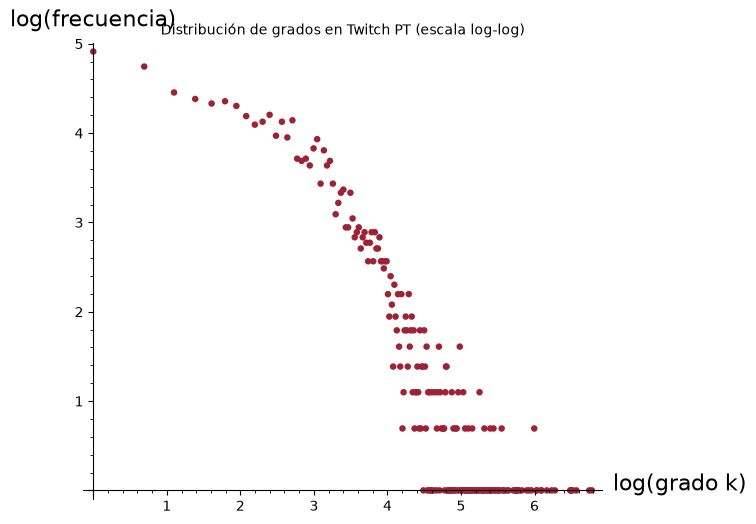

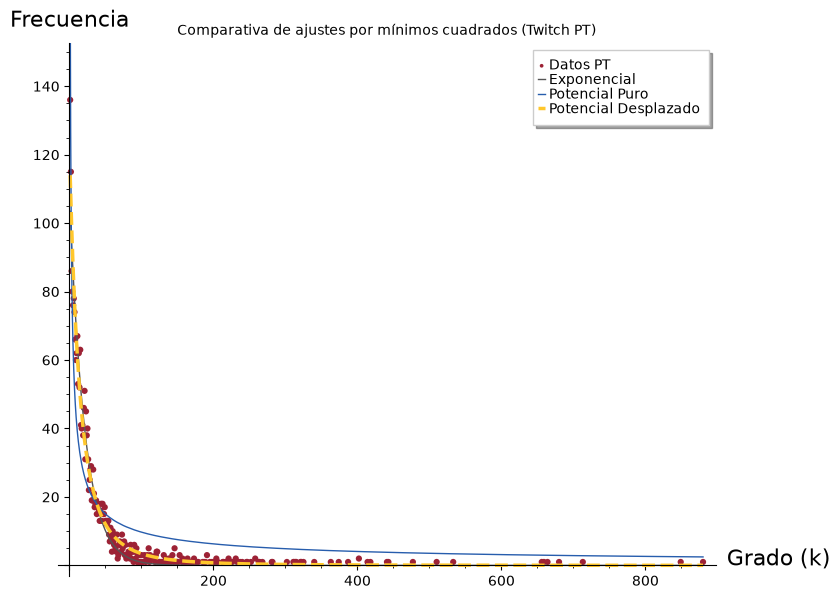

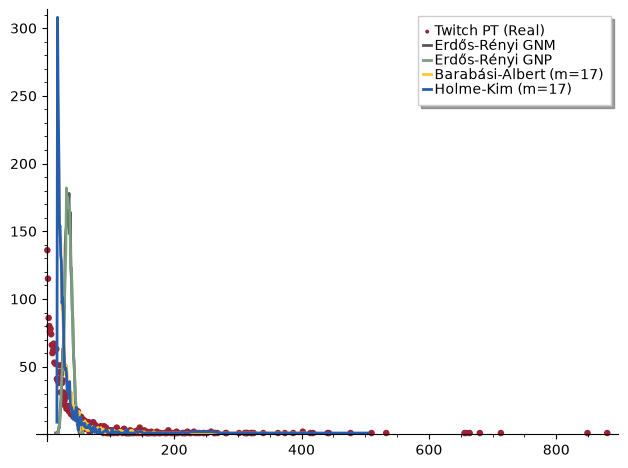

In [8]:
# ==============================================================================
# CELDA 7: GRÁFICAS EN PNG, ATRIBUTOS REALES (SPEARMAN), MODULARIDAD Y 2026
# ==============================================================================
from scipy.stats import spearmanr

# 1. Exportar aristas de PT y ES a datos/salidas/ para la App de Streamlit
for nombre_csv, grafo_exp in [("twitch_PT_edges.csv", G_pt), ("twitch_ES_edges.csv", G_es)]:
    with (CARPETA_SALIDAS / nombre_csv).open("w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["source", "target"])
        w.writerows((u, v) for u, v, _ in grafo_exp.edges())

# 2. Comprobación de triángulos, bipartición y modularidad exacta en PT y ES
print("=== 1. COMUNIDADES, TRIÁNGULOS Y BIPARTICIÓN (PT vs ES 2018) ===")
for etiq, H, res_dic in [("Portugal (PT)", G_pt, res_pt), ("España (ES)", G_es, res_es)]:
    H_nx = res_dic["G_gigante"].networkx_graph()
    coms_h = list(greedy_modularity_communities(H_nx))
    mod_q = nx.algorithms.community.modularity(H_nx, coms_h)
    print(f"{etiq:14s} | Bipartito: {H.is_bipartite()} | Triángulos: {int(H.triangles_count()):,} | "
          f"Comunidades: {len(coms_h)} | Modularidad Q: {float(mod_q):.4f}")

# 3. Correlación de Spearman entre grado y atributos reales (PT y ES)
print("\n=== 2. CORRELACIÓN DE SPEARMAN (GRADO vs ATRIBUTOS REALES) ===")
for etiq, H in [("Portugal (PT)", G_pt), ("España (ES)", G_es)]:
    print(f"-> {etiq}:")
    verts = list(H.vertices())
    gr_vec = [int(H.degree(v)) for v in verts]
    for col in ["views", "life_time", "mature", "affiliate", "dead_account"]:
        vals = [float(atributos_2018[v][col]) for v in verts]
        rho, pval = spearmanr(gr_vec, vals)
        print(f"   {col:14s}: rho = {float(rho):+.4f} (p = {float(pval):.2e})")

# 4. Porcentaje de enlaces del mismo idioma en 2026 (se activa solo cuando tengas los datos)
if RUTAS["2026_edges"].exists():
    tot_26, mismo_26 = 0, 0
    with RUTAS["2026_edges"].open(newline="", encoding="utf-8") as f:
        for fila in csv.DictReader(f):
            tot_26 += 1
            if int(fila.get("same_language", 0)) == 1:
                mismo_26 += 1
    if tot_26 > 0:
        print(f"\n=== 3. HOMOFILIA LINGÜÍSTICA EN CAPTURA PROPIA 2026 (ES+PT) ===")
        print(f"Aristas totales 2026: {tot_26} | Mismo idioma: {mismo_26} ({100.0*mismo_26/tot_26:.2f}%)")

# ==============================================================================
# 5. GENERACIÓN Y GUARDADO DE GRÁFICAS PARA MEMORIA Y DIAPOSITIVAS (PNG)
# ==============================================================================
def perfil_ordenado(H):
    gr = H.degree_sequence()
    fr = Counter(gr)
    return sorted((int(k), int(fr[k])) for k in fr if k > 0)

# Gráfica A: Distribución de grados log-log de PT
g_loglog = list_plot(
    [(math.log(k), math.log(f)) for k, f in datos_ajuste],
    plotjoined=False, color="#9D2235", size=22
)
g_loglog.save(str(CARPETA_SALIDAS / "grafica_1_loglog_PT.png"),
              axes_labels=("log(grado k)", "log(frecuencia)"),
              title="Distribución de grados en Twitch PT (escala log-log)", figsize=7)
g_loglog.show(axes_labels=("log(grado k)", "log(frecuencia)"),
              title="Distribución de grados en Twitch PT (escala log-log)", figsize=7)

# Gráfica B: Comparativa de los 3 ajustes find_fit en PT
f_exp_plot(x) = modelo_exp(x).subs(p_exp)
f_pot_plot(x) = modelo_pot(x).subs(p_pot)
f_desp_plot(x) = modelo_desp(x).subs(p_desp)

g_ajustes = (
    point(datos_ajuste, color="#9D2235", size=20, legend_label="Datos PT") +
    plot(f_exp_plot, (x, 1, max(grados_pt)), color="#555555", legend_label="Exponencial") +
    plot(f_pot_plot, (x, 1, max(grados_pt)), color="#275DAD", legend_label="Potencial Puro") +
    plot(f_desp_plot, (x, 1, max(grados_pt)), color="#FFC72C", thickness=2.5, linestyle="--", legend_label="Potencial Desplazado")
)
g_ajustes.save(str(CARPETA_SALIDAS / "grafica_2_ajustes_PT.png"),
               axes_labels=("Grado (k)", "Frecuencia"),
               title="Comparativa de ajustes por mínimos cuadrados (Twitch PT)",
               ymin=0, ymax=max(f for _, f in datos_ajuste)*1.1, figsize=8)
g_ajustes.show(axes_labels=("Grado (k)", "Frecuencia"),
               title="Comparativa de ajustes por mínimos cuadrados (Twitch PT)",
               ymin=0, ymax=max(f for _, f in datos_ajuste)*1.1, figsize=8)

# Gráfica C: Red real PT vs Modelos Aleatorios (GNM, GNP, BA, HK)
g_modelos = point(datos_ajuste, color="#9D2235", size=22, legend_label="Twitch PT (Real)")
colores_mod = [
    ("Erdős-Rényi GNM", "#555555"),
    ("Erdős-Rényi GNP", "#7A9E7E"),
    (f"Barabási-Albert (m={m_add})", "#FFC72C"),
    (f"Holme-Kim (m={m_add})", "#275DAD"),
]
for nom, col in colores_mod:
    g_modelos += list_plot(perfil_ordenado(modelos[nom]), plotjoined=True, color=col, thickness=2, legend_label=nom)

g_modelos

=== 1. COMPROBACIONES PREVIAS Y ROBUSTEZ EN ESPAÑA (ES 2018) ===
¿Grafo simple no dirigido?: True
¿Apretón de manos (Σ grados = 2m)?: True (171,786 = 2 × 85,893)
¿Es G_es conexo?: False (169 componentes) -> δ(G_es) = 0
Componente gigante ES (5,524 nodos, 85,886 aristas):
  Vértices de corte: 252 | Aristas puente: 295 | δ(G_gig_es) = 1

=== 2. CENTRO, RADIO Y DESIGUALDAD MÉTRICA EN ES 2018 ===
Radio = 4 | Diámetro = 8 | ¿rad <= diam <= 2*rad?: True
Tamaño del Centro Z(G_gig_es): 4 vértices -> Ejemplos: [25951, 143506, 49942, 70486]
Top 5 Cercanía en ES vs pertenencia al Centro:
  ID  25951 | Closeness: 0.51699 | Grado: 1131 | Exc: 4 | ¿En centro?: SÍ
  ID  31958 | Closeness: 0.51215 | Grado: 1098 | Exc: 5 | ¿En centro?: NO
  ID 151558 | Closeness: 0.50572 | Grado: 1015 | Exc: 5 | ¿En centro?: NO
  ID 151200 | Closeness: 0.49618 | Grado:  730 | Exc: 5 | ¿En centro?: NO
  ID 112472 | Closeness: 0.48093 | Grado:  481 | Exc: 5 | ¿En centro?: NO

=== 3. CENTRALIDAD DE BONACICH EN ES 2018 (MA

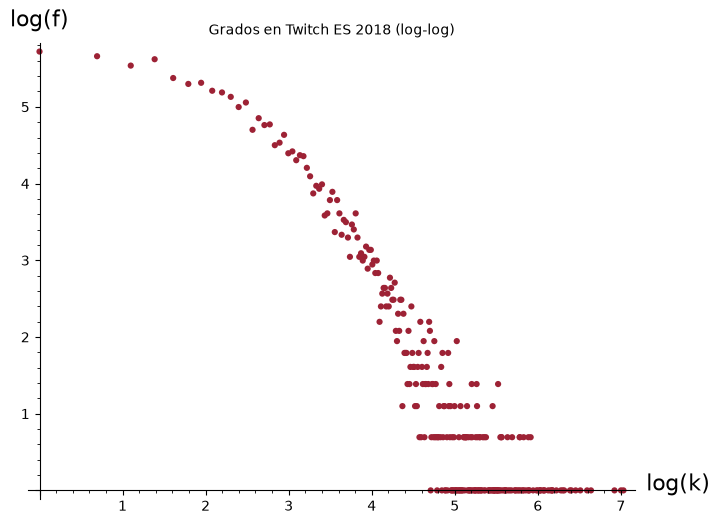

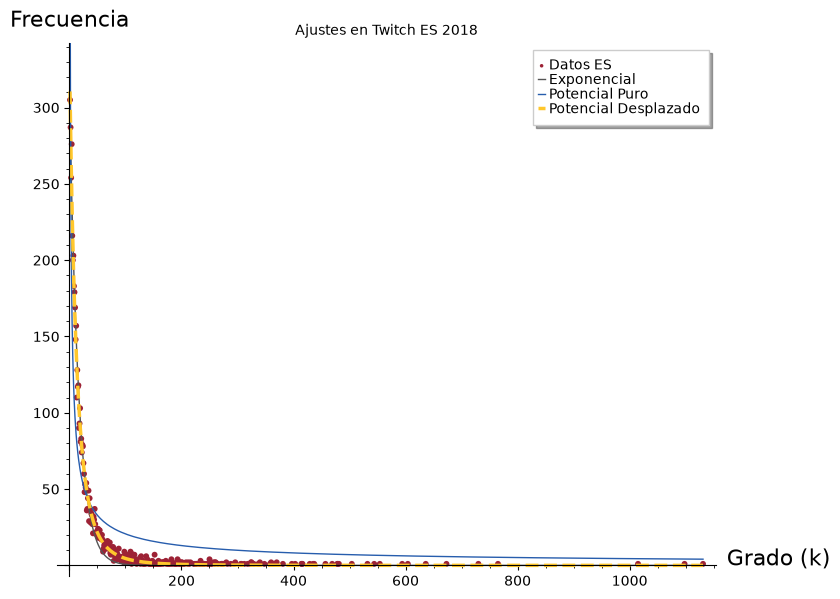

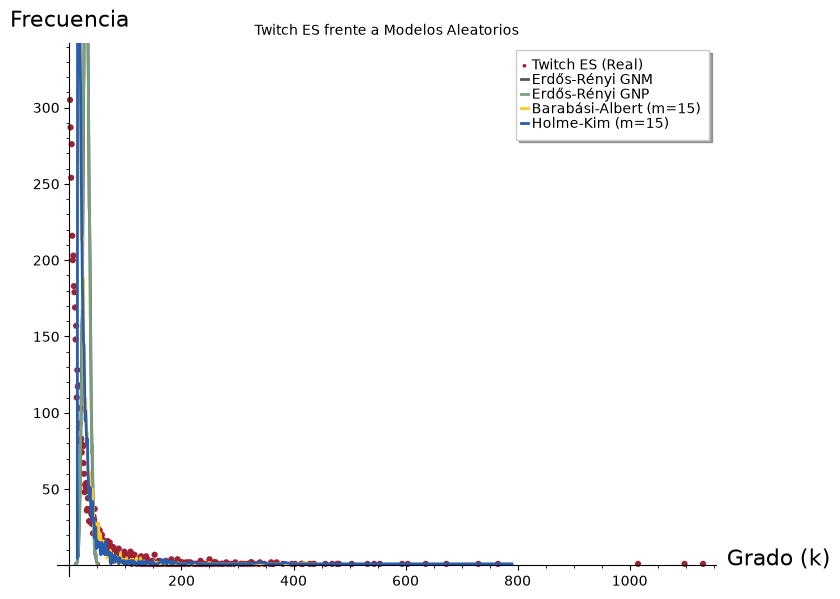


✅ Análisis completo de ES 2018 y gráficas guardados en: /home/andrea/clase/cuarto/MATI/Proyecto-MATI/datos/salidas


In [9]:
# ==============================================================================
# ANÁLISIS COMPLETO EN PROFUNDIDAD DE ESPAÑA (ES 2018) SIN TOPES
# ==============================================================================
import scipy.sparse as sp
import scipy.sparse.linalg as spla

G_gig_es = res_es["G_gigante"]
n_es, m_es = int(G_es.order()), int(G_es.size())
grados_es = [int(G_es.degree(v)) for v in G_es.vertices()]

# 1. PROTOCOLO DE COMPROBACIONES PREVIAS Y ROBUSTEZ (TEOREMA DE WHITNEY)
print("=== 1. COMPROBACIONES PREVIAS Y ROBUSTEZ EN ESPAÑA (ES 2018) ===")
print(f"¿Grafo simple no dirigido?: {(not G_es.has_loops()) and (not G_es.has_multiple_edges())}")
print(f"¿Apretón de manos (Σ grados = 2m)?: {sum(grados_es) == 2 * m_es} ({sum(grados_es):,} = 2 × {m_es:,})")
print(f"¿Es G_es conexo?: {G_es.is_connected()} ({G_es.connected_components_number()} componentes) -> δ(G_es) = {min(grados_es)}")

bloques_es, v_corte_es = G_gig_es.blocks_and_cut_vertices()
puentes_es = list(G_gig_es.bridges())
print(f"Componente gigante ES ({int(G_gig_es.order()):,} nodos, {int(G_gig_es.size()):,} aristas):")
print(f"  Vértices de corte: {len(v_corte_es)} | Aristas puente: {len(puentes_es)} | δ(G_gig_es) = {min(G_gig_es.degree())}")

# 2. CENTRO, RADIO, DIÁMETRO Y DESIGUALDAD MÉTRICA EN ES (SIN TOPE)
print("\n=== 2. CENTRO, RADIO Y DESIGUALDAD MÉTRICA EN ES 2018 ===")
exc_es = {v: int(e) for v, e in zip(G_gig_es.vertices(), G_gig_es.eccentricity())}
radio_es, diam_es = min(exc_es.values()), max(exc_es.values())
centro_es = [v for v, e in exc_es.items() if e == radio_es]
print(f"Radio = {radio_es} | Diámetro = {diam_es} | ¿rad <= diam <= 2*rad?: {radio_es <= diam_es <= 2*radio_es}")
print(f"Tamaño del Centro Z(G_gig_es): {len(centro_es)} vértices -> Ejemplos: {centro_es[:8]}")

print("Top 5 Cercanía en ES vs pertenencia al Centro:")
for v, val in top_diccionario(res_es["c_cerca"], 5):
    print(f"  ID {v:6d} | Closeness: {float(val):.5f} | Grado: {G_gig_es.degree(v):4d} | Exc: {exc_es[v]} | ¿En centro?: {'SÍ' if v in centro_es else 'NO'}")

# 3. CENTRALIDAD DE BONACICH EN ES USANDO MATRICES DISPERSAS (O(n+m), < 1 segundo)
print("\n=== 3. CENTRALIDAD DE BONACICH EN ES 2018 (MATRIZ DISPERSA) ===")
nodos_ord_es = sorted(G_gig_es.vertices())
idx_es = {v: i for i, v in enumerate(nodos_ord_es)}
n_gig_es = int(len(nodos_ord_es))

filas_sp, cols_sp = [], []
for u, v in G_gig_es.edges(labels=False):
    iu, iv = idx_es[u], idx_es[v]
    filas_sp.extend([iu, iv])
    cols_sp.extend([iv, iu])

A_sp = sp.csc_matrix(
    (np.ones(int(len(filas_sp)), dtype=float), (filas_sp, cols_sp)),
    shape=(n_gig_es, n_gig_es)
)
lambda_max_es = float(spla.eigsh(A_sp, k=int(1), which="LM", return_eigenvectors=False)[0])
alpha_es = float(0.5) / lambda_max_es
I_sp = sp.eye(n_gig_es, format="csc")
unos_es = np.ones(n_gig_es, dtype=float)

c_bon_es = spla.spsolve(I_sp - alpha_es * A_sp, A_sp.dot(unos_es))
c_bon_es = c_bon_es / float(np.linalg.norm(c_bon_es))
dic_bon_es = {nodos_ord_es[i]: float(c_bon_es[i]) for i in range(n_gig_es)}

print(f"lambda_max = {lambda_max_es:.4f} | cota 1/lambda_max = {1.0/lambda_max_es:.5f} | alpha = {alpha_es:.5f}")
for v, val in top_diccionario(dic_bon_es, 5):
    print(f"  ID {v:6d} | Bonacich: {val:.5f} | Grado: {G_gig_es.degree(v):4d} | Autovector: {float(res_es['c_vec'][v]):.5f} | Views: {atributos_2018[v]['views']}")

# 4. SIMULACIÓN DE ATAQUE DIRIGIDO A ES (ELIMINANDO TOP 20)
print("\n=== 4. SIMULACIÓN DE ATAQUE DIRIGIDO A ES 2018 (ELIMINANDO 20 NODOS) ===")
top20_inter_es = [v for v, _ in top_diccionario(res_es["c_inter"], 20)]
top20_vec_es = [v for v, _ in top_diccionario(res_es["c_vec"], 20)]
set_random_seed(2026)
azar20_es = sample(list(G_gig_es.vertices()), 20)

for etiq, borrar in [("Original", []), ("Fallo aleatorio (20)", azar20_es),
                     ("Ataque Autovector (Top 20)", top20_vec_es), ("Ataque Puentes (Top 20)", top20_inter_es)]:
    H_tmp = G_gig_es.copy()
    if borrar:
        H_tmp.delete_vertices(borrar)
    cs = sorted(H_tmp.connected_components(), key=len, reverse=True)
    print(f"  {etiq:30s} -> Componentes: {len(cs):2d} | Comp. mayor: {len(cs[0]):4d} nodos")

# 5. AJUSTE LEY DE POTENCIAS (find_fit) Y MODELOS ALEATORIOS EN ES
print("\n=== 5. AJUSTES POR MÍNIMOS CUADRADOS (SSE) EN ESPAÑA (ES 2018) ===")
frec_es = Counter(grados_es)
datos_es = sorted((int(k), int(f)) for k, f in frec_es.items() if k > 0 and f > 0)

var('x a b c')
m_exp_es(x) = a * exp(b * x)
m_pot_es(x) = a * (x^b)
m_desp_es(x) = a * abs(x - c)^b

g_max_es = max(f for _, f in datos_es)
p_exp_es = find_fit(datos_es, m_exp_es, initial_guess=[g_max_es, -0.05], solution_dict=True)
p_pot_es = find_fit(datos_es, m_pot_es, initial_guess=[g_max_es, -1.0], solution_dict=True)
p_desp_es = find_fit(datos_es, m_desp_es, initial_guess=[g_max_es, -1.5, -5.0], solution_dict=True)

def sse_es(mod, pars):
    return float(sum((f - float(mod(k).subs(pars)))**2 for k, f in datos_es))

print(f"SSE Potencial Puro:       {sse_es(m_pot_es, p_pot_es):.2f}")
print(f"SSE Exponencial:          {sse_es(m_exp_es, p_exp_es):.2f}")
print(f"SSE Potencial Desplazado: {sse_es(m_desp_es, p_desp_es):.2f} (Parámetros: { {str(k): round(float(v), 4) for k, v in p_desp_es.items()} })")

p_er_es = float(2.0 * m_es) / float(n_es * (n_es - 1))
m_add_es = int(max(1, round(m_es / n_es)))
set_random_seed(2026)
modelos_es = {
    "Twitch ES (Real)": G_es,
    "Erdős-Rényi GNM": graphs.RandomGNM(n_es, m_es),
    "Erdős-Rényi GNP": graphs.RandomGNP(n_es, p_er_es),
    f"Barabási-Albert (m={m_add_es})": graphs.RandomBarabasiAlbert(n_es, m_add_es),
    f"Holme-Kim (m={m_add_es})": graphs.RandomHolmeKim(n_es, m_add_es, 0.5)
}
print("\n=== 6. RED REAL ES vs MODELOS GENERADORES ===")
for nom, H in modelos_es.items():
    print(f"  {nom:26s} -> Aristas: {int(H.size()):6d} | G.Medio: {float(H.average_degree()):5.2f} | Clustering: {float(H.clustering_average()):.4f}")

# 6. VERIFICACIÓN CONSTRUCTIVA HAVEL-HAKIMI EN LOS 6 HUBS DE ES
seis_hubs_es = [v for v, _ in top_diccionario(res_es["c_grado"], 6)]
H6_es = G_es.subgraph(seis_hubs_es)
sec_es = sorted([int(H6_es.degree(v)) for v in H6_es.vertices()], reverse=True)
print(f"\n=== 7. HAVEL-HAKIMI EN LOS 6 MAYORES HUBS DE ES ({seis_hubs_es}) ===")
seq_t = list(sec_es)
paso = 0
print(f"  Paso {paso}: {seq_t}")
while seq_t and seq_t[0] > 0:
    k = seq_t.pop(0)
    for i in range(k): seq_t[i] -= 1
    seq_t.sort(reverse=True)
    paso += 1
    print(f"  Paso {paso}: {seq_t}")

# 7. GRÁFICAS PNG DE ESPAÑA (SIN SOLAPAMIENTO DE ETIQUETAS)
def perfil_ord(H):
    fr = Counter(H.degree_sequence())
    return sorted((int(k), int(fr[k])) for k in fr if k > 0)

g1_es = list_plot([(math.log(k), math.log(f)) for k, f in datos_es], plotjoined=False, color="#9D2235", size=20)
g1_es.save(str(CARPETA_SALIDAS / "grafica_ES_1_loglog.png"),
           axes_labels=("log(k)", "log(f)"), title="Grados en Twitch ES 2018 (log-log)", figsize=7)
g1_es.show(axes_labels=("log(k)", "log(f)"), title="Grados en Twitch ES 2018 (log-log)", figsize=7)

f_exp_e(x) = m_exp_es(x).subs(p_exp_es)
f_pot_e(x) = m_pot_es(x).subs(p_pot_es)
f_desp_e(x) = m_desp_es(x).subs(p_desp_es)
g2_es = (
    point(datos_es, color="#9D2235", size=18, legend_label="Datos ES") +
    plot(f_exp_e, (x, 1, max(grados_es)), color="#555555", legend_label="Exponencial") +
    plot(f_pot_e, (x, 1, max(grados_es)), color="#275DAD", legend_label="Potencial Puro") +
    plot(f_desp_e, (x, 1, max(grados_es)), color="#FFC72C", thickness=2.5, linestyle="--", legend_label="Potencial Desplazado")
)
g2_es.save(str(CARPETA_SALIDAS / "grafica_ES_2_ajustes.png"),
           axes_labels=("Grado (k)", "Frecuencia"), title="Ajustes en Twitch ES 2018",
           ymin=0, ymax=g_max_es * 1.1, figsize=8)
g2_es.show(axes_labels=("Grado (k)", "Frecuencia"), title="Ajustes en Twitch ES 2018",
           ymin=0, ymax=g_max_es * 1.1, figsize=8)

g3_es = point(datos_es, color="#9D2235", size=20, legend_label="Twitch ES (Real)")
for nom, col in [("Erdős-Rényi GNM", "#555555"), ("Erdős-Rényi GNP", "#7A9E7E"),
                 (f"Barabási-Albert (m={m_add_es})", "#FFC72C"), (f"Holme-Kim (m={m_add_es})", "#275DAD")]:
    g3_es += list_plot(perfil_ord(modelos_es[nom]), plotjoined=True, color=col, thickness=2, legend_label=nom)

g3_es.save(str(CARPETA_SALIDAS / "grafica_ES_3_modelos.png"),
           axes_labels=("Grado (k)", "Frecuencia"), title="Twitch ES frente a Modelos Aleatorios",
           ymin=0, ymax=g_max_es * 1.1, figsize=8)
g3_es.show(axes_labels=("Grado (k)", "Frecuencia"), title="Twitch ES frente a Modelos Aleatorios",
           ymin=0, ymax=g_max_es * 1.1, figsize=8)

print("\n✅ Análisis completo de ES 2018 y gráficas guardados en:", CARPETA_SALIDAS.resolve())

<h1>Generar gráficos</h1>

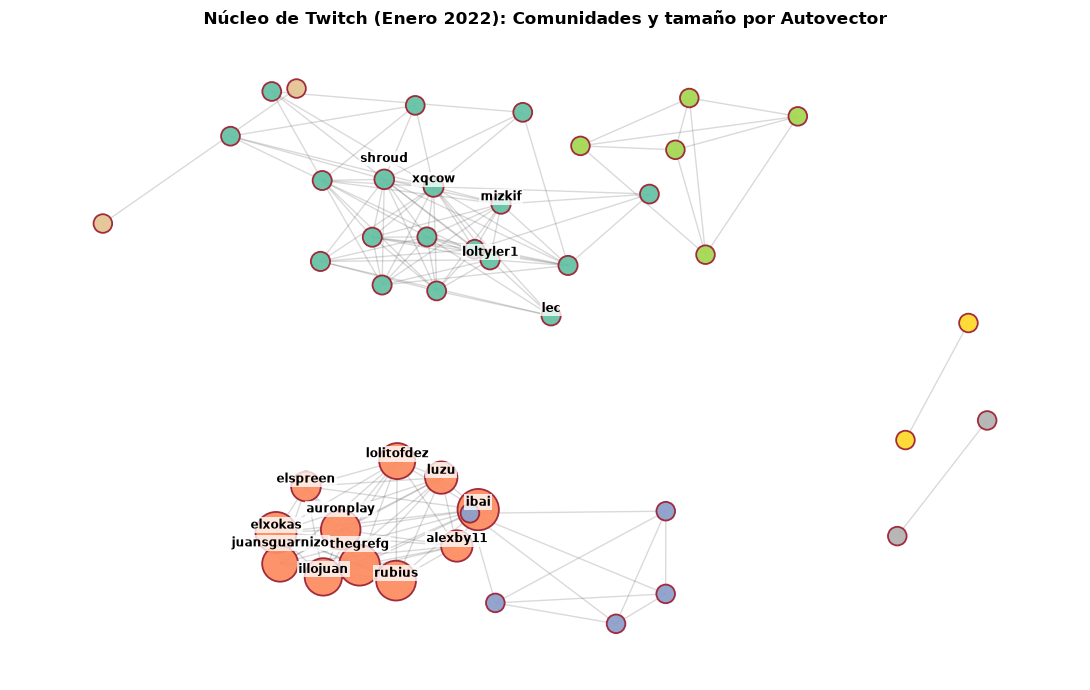

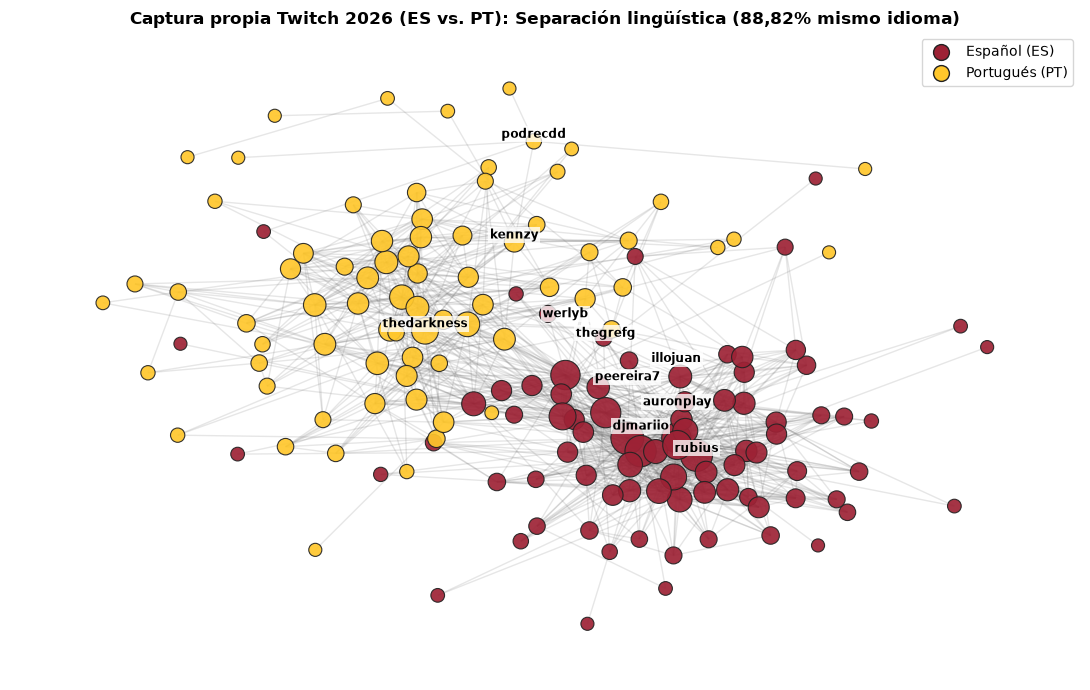

✅ Imágenes regeneradas y limpias en datos/salidas/


In [14]:
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms.community import greedy_modularity_communities

def separar_etiquetas(pos, nodos_etiq, dx=0.18, dy=0.055):
    """Evita que las etiquetas se monten unas encima de otras."""
    pos_lbl = {}
    orden = sorted(nodos_etiq, key=lambda u: (float(pos[u][1]), float(pos[u][0])))
    for u in orden:
        x, y = float(pos[u][0]), float(pos[u][1])
        y_try = y + float(0.025)
        for _ in range(int(15)):
            if not any(abs(x - ox) < float(dx) and abs(y_try - oy) < float(dy) for ox, oy in pos_lbl.values()):
                break
            y_try += float(dy)
        pos_lbl[u] = (x, y_try)
    return pos_lbl

ESTILO_CAJA = dict(facecolor="white", edgecolor="none", alpha=float(0.78), pad=float(1.1))

# ==============================================================================
# 1. GRÁFICA DEL NÚCLEO DE ENERO 2022 (SIN CUADRADOS COREANOS NI SOLAPAMIENTOS)
# ==============================================================================
# Recuperamos los nombres ASCII originales desde 2022-01-nodes.csv para evitar caracteres Hangul
lbl_a_ascii = {}
if RUTAS["2022_nodes"].exists():
    with RUTAS["2022_nodes"].open(newline="", encoding="utf-8-sig", errors="ignore") as fn:
        for fila in csv.DictReader(fn):
            nid = (fila.get("Id") or fila.get("id") or "").strip().lower()
            lbl = (fila.get("Label") or fila.get("label") or "").strip().lower()
            if nid and lbl and nid.isascii():
                lbl_a_ascii[lbl] = nid

G22_nx = G_2022.networkx_graph()
top45 = [u for u, _ in sorted(G22_nx.degree, key=lambda x: x[1], reverse=True)[:int(45)]]
G22_sub = G22_nx.subgraph(top45).copy()

coms22 = list(greedy_modularity_communities(G22_sub))
mapa_col = {n: int(i) for i, c in enumerate(coms22) for n in c}
eigen22 = nx.eigenvector_centrality(G22_nx, max_iter=int(600))

etiquetas22 = {}
cont_kr = int(1)
for u in G22_sub.nodes():
    if u.isascii():
        etiquetas22[u] = u
    else:
        etiquetas22[u] = lbl_a_ascii.get(u, f"kr_canal_{cont_kr}")
        cont_kr += int(1)

fig, ax = plt.subplots(figsize=(int(11), int(7.5)))
pos22 = nx.spring_layout(G22_sub, seed=int(42), k=float(0.75))
tamanos22 = [float(180 + 2600 * float(eigen22[u])) for u in G22_sub.nodes()]
colores22 = [mapa_col[u] for u in G22_sub.nodes()]

nx.draw_networkx_nodes(
    G22_sub, pos22, node_size=tamanos22, node_color=colores22,
    cmap=plt.cm.Set2, edgecolors="#9D2235", linewidths=float(1.3), alpha=float(0.95), ax=ax
)
nx.draw_networkx_edges(G22_sub, pos22, alpha=float(0.22), edge_color="#555555", ax=ax)

# Etiquetamos los 28 nodos más relevantes para mantener la imagen limpia
top_lbl22 = sorted(
    G22_sub.nodes(),
    key=lambda n: float(eigen22[n]) + float(G22_nx.degree(n)) / float(500),
    reverse=True
)[:int(16)]
pos_lbl22 = separar_etiquetas(pos22, top_lbl22, dx=float(0.14), dy=float(0.045))
nx.draw_networkx_labels(
    G22_sub, pos_lbl22, labels={u: etiquetas22[u] for u in top_lbl22},
    font_size=float(8.5), font_weight="bold", bbox=ESTILO_CAJA, ax=ax
)

ax.set_title("Núcleo de Twitch (Enero 2022): Comunidades y tamaño por Autovector", fontsize=int(12), fontweight="bold")
ax.axis("off")
fig.tight_layout()
fig.savefig("datos/salidas/grafica_nucleo_2022.png", dpi=int(240), bbox_inches="tight")
plt.show()

# ==============================================================================
# 2. GRÁFICA DE TU CAPTURA PROPIA 2026 (ETIQUETAS LIMPIAS Y SEPARADAS)
# ==============================================================================
idioma_26 = {}
with RUTAS["2026_nodes"].open(newline="", encoding="utf-8") as fn:
    for fila in csv.DictReader(fn):
        idioma_26[fila["login"].strip().lower()] = fila["language"].strip().upper()

G26_gig = G_2026.subgraph(max(G_2026.connected_components(), key=len)).networkx_graph()
bet26 = nx.betweenness_centrality(G26_gig, normalized=True)

fig2, ax2 = plt.subplots(figsize=(int(11), int(7.5)))
pos26 = nx.spring_layout(G26_gig, seed=int(2026), k=float(0.55))

colores26 = ["#9D2235" if idioma_26.get(u, "ES") == "ES" else "#FFC72C" for u in G26_gig.nodes()]
tamanos26 = [float(80 + 480 * (float(G26_gig.degree(u)) / float(55))) for u in G26_gig.nodes()]

nx.draw_networkx_nodes(
    G26_gig, pos26, node_size=tamanos26, node_color=colores26,
    edgecolors="#222222", linewidths=float(0.8), alpha=float(0.92), ax=ax2
)
nx.draw_networkx_edges(G26_gig, pos26, alpha=float(0.16), edge_color="#666666", ax=ax2)

# Seleccionamos los 8 mayores hubs + los 6 mayores puentes para evitar aglomeración
top_g26 = {u for u, _ in sorted(G26_gig.degree, key=lambda x: x[1], reverse=True)[:int(8)]}
top_b26 = {u for u, _ in sorted(bet26.items(), key=lambda x: x[1], reverse=True)[:int(6)]}
sel_etiq26 = list(top_g26 | top_b26)

pos_lbl26 = separar_etiquetas(pos26, sel_etiq26, dx=0.22, dy=0.065)
nx.draw_networkx_labels(
    G26_gig, pos_lbl26, labels={u: u for u in sel_etiq26},
    font_size=float(8.5), font_weight="bold", bbox=ESTILO_CAJA, ax=ax2
)

ax2.scatter([], [], c="#9D2235", s=int(130), edgecolors="#222222", label="Español (ES)")
ax2.scatter([], [], c="#FFC72C", s=int(130), edgecolors="#222222", label="Portugués (PT)")
ax2.legend(loc="upper right", frameon=True, fontsize=int(10))
ax2.set_title("Captura propia Twitch 2026 (ES vs. PT): Separación lingüística (88,82% mismo idioma)", fontsize=int(12), fontweight="bold")
ax2.axis("off")
fig2.tight_layout()
fig2.savefig("datos/salidas/grafica_red_2026.png", dpi=int(240), bbox_inches="tight")
plt.show()
print("✅ Imágenes regeneradas y limpias en datos/salidas/")